# CyberShield — Cyberbullying Detection and Prevention Using Deep Learning
## Stage 1: Custom Deep Learning Model Training Pipeline (1D CNN)

### 1.1 Project Overview
Cyberbullying, harassment, and toxic interactions on social media platforms pose severe emotional and psychological threats. In multilingual digital spaces (especially in India), online hostility frequently occurs in **Hinglish** (a blend of Hindi and English written using the Latin alphabet) alongside standard English. Standard off-the-shelf keyword blacklists and English-only models fail to grasp colloquial, misspelled, or phonetically written Hinglish insults.

**CyberShield** addresses this challenge by designing and training a dedicated **1-Dimensional Convolutional Neural Network (1D CNN)** from scratch for binary text classification:
- **Class 0:** Non-Bullying / Neutral / Safe text
- **Class 1:** Cyberbullying / Toxic / Harassment

### 1.2 Why a Custom 1D CNN? (Viva & Theoretical Highlights)
- **Local Feature Extraction (N-gram capture):** 1D convolutions slide learnable filters across contiguous word embedding vectors, capturing localized multi-word abusive phrases and slurs regardless of their position in the text.
- **Computational & Real-time Efficiency:** 1D CNNs have significantly fewer parameters and require far lower compute latency than heavy Transformers (BERT/RoBERTa) or recurrent networks (LSTM/GRU), making them ideal for low-latency chat moderation.
- **Learned From Scratch:** The embedding layer is randomly initialized and trained end-to-end on Hinglish/English vocabulary, directly adapting to informal colloquial terminology without relying on out-of-domain pretrained weights.

### 1.3 End-to-End Pipeline Roadmap
1. **Project Introduction**
2. **Import Libraries**
3. **Dataset Loading**
4. **Dataset Inspection**
5. **Label Verification & Mapping**
6. **Text Preprocessing & Negation Preservation**
7. **Train-Validation-Test Split (Data Leakage Prevention)**
8. **Tokenization and Padding**
9. **CNN Architecture Design**
10. **Model Compilation**
11. **Model Training with Imbalance Mitigation & Callbacks**
12. **Model Evaluation on Holdout Test Set**
13. **Training Visualization (Loss, Accuracy & Confusion Matrix)**
14. **Model & Preprocessing Serialization for Deployment**
15. **Conclusion & Viva Defense Summary**

## 2. Import Libraries
We import essential scientific computing, data manipulation, visualization, evaluation, and deep learning modules using TensorFlow/Keras and Scikit-Learn.
Random seeds are initialized for experimental reproducibility.

In [1]:
import os
import re
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn utilities for splitting, class balancing, and metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# TensorFlow and Keras components
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Set seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print(f"TensorFlow Version: {tf.__version__}")
print("All required libraries imported successfully.")

TensorFlow Version: 2.21.0
All required libraries imported successfully.


## 3. Dataset Loading
The dataset is stored in `Dataset/final_dataset_hinglish.csv`. We load it into a pandas DataFrame and verify file presence.

In [2]:
DATASET_PATH = os.path.join('Dataset', 'final_dataset_hinglish.csv')

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Dataset not found at expected location: {DATASET_PATH}")

df = pd.read_csv(DATASET_PATH)
print(f"Dataset loaded successfully from: {DATASET_PATH}")

Dataset loaded successfully from: Dataset\final_dataset_hinglish.csv


## 4. Dataset Inspection
Before performing any preprocessing or model building, we perform exploratory inspection:
1. Preview first 5 rows.
2. Check dataset shape (rows and columns).
3. Check column names and data types.
4. Check for missing (NaN) values.
5. Check for duplicate records.
6. Inspect raw label frequency distribution.

In [3]:
# Display first 5 rows
print("--- First 5 Records ---")
df.head()

--- First 5 Records ---


,headline,label
0,cock suck before you piss around on my work,-1
1,you are gay or antisemmitian archangel white ...,-1
2,fuck your filthy mother in the ass dry,-1
3,get fuck ed up get fuck ed up got a drink t...,-1
4,stupid peace of shit stop deleting my stuff ...,-1


In [4]:
# Check dataset dimensions and column data types
print("--- Dataset Shape ---")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}\n")

print("--- Column Information ---")
df.info()

--- Dataset Shape ---
Total Rows: 18148, Total Columns: 2

--- Column Information ---
<class 'pandas.DataFrame'>
RangeIndex: 18148 entries, 0 to 18147
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   headline  18148 non-null  str  
 1   label     18148 non-null  int64
dtypes: int64(1), str(1)
memory usage: 283.7 KB


In [5]:
# Check missing values and duplicate rows
print("--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows Check ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

--- Missing Values Check ---
headline    0
label       0
dtype: int64

--- Duplicate Rows Check ---
Number of duplicate rows: 1079


In [6]:
# Raw label distribution
print("--- Raw Label Distribution ---")
raw_counts = df['label'].value_counts(dropna=False)
raw_percent = df['label'].value_counts(normalize=True, dropna=False) * 100

dist_df = pd.DataFrame({'Count': raw_counts, 'Percentage (%)': raw_percent.round(2)})
print(dist_df)

--- Raw Label Distribution ---
       Count  Percentage (%)
label                       
-1     11661           64.26
 0      6487           35.74


## 5. Label Verification
> [!WARNING]
> **Crucial Step — Never Assume Label Semantics Without Verification:**
> Datasets from different sources encode labels differently (e.g., -1/0, 0/1, 1/-1). In this dataset, raw label values are `[-1, 0]`.
> We must empirically inspect sample text messages associated with each unique label to confirm their exact semantic meaning before mapping them for binary cross-entropy.

In [7]:
# Inspect sample messages from each unique label value
unique_labels = sorted(df['label'].dropna().unique())
print(f"Unique label values found: {unique_labels}\n")

for lbl in unique_labels:
    print("=" * 60)
    print(f"Sample messages corresponding to raw label: {lbl}")
    print("=" * 60)
    sample_texts = df[df['label'] == lbl]['headline'].dropna().head(5)
    for i, msg in enumerate(sample_texts, 1):
        print(f"{i}. {msg[:120]}...")
    print("\n")

Unique label values found: [np.int64(-1), np.int64(0)]

Sample messages corresponding to raw label: -1
1. cock  suck before you piss around on my work...
2. you are  gay or antisemmitian archangel white tiger  meow  greetingsh uh  there are two ways  why you do erased my comme...
3. fuck your filthy mother in the ass  dry...
4. get fuck  ed up  get fuck  ed up got a drink that you cant put down get fuck up get fuck  ed up i m fuck  ed up right no...
5. stupid peace of  shit  stop deleting my stuff  ass hole  go die and fall in a hole go to hell...


Sample messages corresponding to raw label: 0
1. explanation why the edits made under my username hardcore metallica fan were reverted  they weren t vandalisms  just clo...
2. d aww  he matches this background colour i m seemingly stuck with  thanks  talk january utc...
3. hey man  i m really not trying to edit war  it s just that this guy is constantly removing relevant information and talk...
4. more i can t make any real suggestions on i

### Empirical Verification Findings & Target Label Definition
From inspecting the sample texts above:
- **Raw Label `-1`:** Contains severe vulgarity, profanities, hate speech, and personal harassment in English and Hinglish. Therefore, **`-1` indicates Cyberbullying / Toxic**.
- **Raw Label `0`:** Contains constructive discussions, neutral commentary, and harmless Hinglish/English conversation. Therefore, **`0` indicates Non-Bullying / Neutral**.

For standard deep learning binary classification with Sigmoid activation:
- **Class `0` = Non-Bullying (Normal/Safe)**
- **Class `1` = Cyberbullying (Abusive/Toxic)**

Thus, we define the explicit mapping: `{-1: 1, 0: 0}` and verify that every record is correctly mapped.

In [8]:
# Define verified label mapping dictionary
LABEL_MAPPING = {
    -1: 1,  # -1 (Abusive/Toxic) -> 1 (Cyberbullying)
     0: 0   #  0 (Benign/Neutral) -> 0 (Non-Bullying)
}

# Verify that no unmapped labels exist
unmapped = set(df['label'].unique()) - set(LABEL_MAPPING.keys())
if unmapped:
    raise ValueError(f"CRITICAL ERROR: Found unexpected unmapped label(s): {unmapped}! Review dataset.")

# Create target column
df['target'] = df['label'].map(LABEL_MAPPING)

print("Label mapping successfully verified and applied:")
print("  0 -> Non-Bullying (Safe/Normal)")
print("  1 -> Cyberbullying (Abusive/Toxic)")
print("\n--- Target Class Distribution ---")
print(df['target'].value_counts())

Label mapping successfully verified and applied:
  0 -> Non-Bullying (Safe/Normal)
  1 -> Cyberbullying (Abusive/Toxic)

--- Target Class Distribution ---
target
1    11661
0     6487
Name: count, dtype: int64


## 6. Text Preprocessing
Social media text contains slang, emojis, URLs, and noisy symbols. Preprocessing cleans the input while preserving critical semantic cues.

### Stopwords & Negation Handling Rules:
1. **Never Remove Negation Words:**
   - English & Hinglish negation words (e.g., `not`, `no`, `nahi`, `nahin`, `na`, `mat`, `never`, `neither`, `nor`) directly invert sentiment and insult meaning.
   - Removing them would destroy the grammatical context (e.g., *"tu acha nahi hai"* would become *"tu acha hai"*).
2. **Preserve Abusive Vocabulary:**
   - Abusive words must **never** be filtered out because the CNN must learn their patterns and associations with cyberbullying.
3. **Cleaning Steps:**
   - Handle null text.
   - Lowercase the text.
   - Remove URLs and HTML markup.
   - Strip non-alphanumeric punctuation while retaining alphanumeric words.
   - Filter general stopwords while strictly exempting negations.

In [9]:
STOPWORDS_PATH = os.path.join('Dataset', 'stopwords.txt')

# Essential negation words that must NEVER be removed
NEGATION_WORDS = {
    'not', 'no', 'nor', 'neither', 'never', 'none',
    'nahi', 'nahin', 'na', 'mat', 'nhi', 'ni'
}

active_stopwords = set()
if os.path.exists(STOPWORDS_PATH):
    with open(STOPWORDS_PATH, 'r', encoding='utf-8') as f:
        raw_stopwords = {line.strip().lower() for line in f if line.strip()}
    
    # Exclude negation words from the stopword set
    active_stopwords = raw_stopwords - NEGATION_WORDS
    print(f"Loaded {len(raw_stopwords)} raw stopwords.")
    print(f"Exempted {len(NEGATION_WORDS)} negation words.")
    print(f"Active stopwords count for filtering: {len(active_stopwords)}")
else:
    print(f"Notice: {STOPWORDS_PATH} not found. Skipping stopword removal.")

Loaded 1069 raw stopwords.
Exempted 12 negation words.
Active stopwords count for filtering: 1058


In [11]:
def clean_text(text, stopwords_set=active_stopwords):
    """
    Preprocesses raw English/Hinglish text:
    - Handles missing/null text gracefully
    - Converts to lowercase
    - Strips URLs and HTML tags
    - Strips non-alphanumeric characters while keeping word tokens
    - Filters general stopwords while preserving negations
    """
    if not isinstance(text, str):
        return ""
    
    # Lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    
    # Remove special characters, numbers, and punctuation
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # Tokenize by whitespace
    tokens = text.split()
    
    # Retain tokens: keep if length > 1 and (not in stopwords OR is a negation word)
    retained = [w for w in tokens if len(w) > 1 and (w not in stopwords_set or w in NEGATION_WORDS)]
    
    return " ".join(retained)

# Demonstration: verify negation preservation
sample_input = "bhai tu kisi kaam ka nahi hai, please do not talk to me!"
print("Sample Input:    ", sample_input)
print("Cleaned Output:  ", clean_text(sample_input))

Sample Input:     bhai tu kisi kaam ka nahi hai, please do not talk to me!
Cleaned Output:   kaam nahi not talk


In [12]:
# Apply text preprocessing across the dataset
df['headline'] = df['headline'].fillna('')
df['cleaned_text'] = df['headline'].apply(clean_text)

# Remove empty rows after cleaning
initial_len = len(df)
df = df[df['cleaned_text'].str.strip() != ''].copy().reset_index(drop=True)
print(f"Preprocessed {len(df)} records (dropped {initial_len - len(df)} empty rows after cleaning).")

# Preview cleaned samples
df[['headline', 'cleaned_text', 'target']].head()

Preprocessed 18125 records (dropped 23 empty rows after cleaning).


,headline,cleaned_text,target
0,cock suck before you piss around on my work,cock suck piss work,1
1,you are gay or antisemmitian archangel white ...,gay antisemmitian archangel white tiger meow g...,1
2,fuck your filthy mother in the ass dry,fuck filthy mother ass dry,1
3,get fuck ed up get fuck ed up got a drink t...,fuck ed fuck ed drink put fuck fuck ed fuck ed,1
4,stupid peace of shit stop deleting my stuff ...,stupid peace shit stop deleting stuff ass hole...,1


## 7. Train, Validation, and Test Split
### Strict Prevention of Data Leakage
- **Training Set (70%):** Used exclusively for fitting the tokenizer and training the neural network.
- **Validation Set (15%):** Used for monitoring validation loss, tuning early stopping, and saving the best checkpoint.
- **Test Set (15%):** Holdout set untouched during training, used solely for final unbiased model evaluation.
- **Stratification:** We use `stratify=y` so all three subsets mirror the exact class ratio of the dataset.
- **Data Leakage Safeguard:** Splitting occurs **BEFORE** fitting the Tokenizer. The tokenizer must never see validation or test data during vocabulary construction.

In [13]:
X = df['cleaned_text'].values
y = df['target'].values

# Step 1: 70% Train, 30% Temp (Val + Test) with stratification
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=y
)

# Step 2: Split 30% Temp into 15% Validation and 15% Test with stratification
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

print(f"Training set:   {len(X_train_raw)} samples ({len(X_train_raw)/len(X)*100:.1f}%)")
print(f"Validation set: {len(X_val_raw)} samples ({len(X_val_raw)/len(X)*100:.1f}%)")
print(f"Test set:       {len(X_test_raw)} samples ({len(X_test_raw)/len(X)*100:.1f}%)")

Training set:   12687 samples (70.0%)
Validation set: 2719 samples (15.0%)
Test set:       2719 samples (15.0%)


## 8. Tokenization and Sequence Padding
Neural networks process dense numeric matrices, not raw strings. We convert text into integer sequences and pad them to a uniform length.

### Hyperparameters:
- `MAX_VOCAB_SIZE = 15000`: Caps vocabulary to the top 15,000 words. Rare tokens map to `<OOV>`.
- `MAX_SEQUENCE_LENGTH = 100`: Fixed sequence length suitable for chat comments. Shorter sentences are post-padded with 0; longer sentences are truncated.
- `EMBEDDING_DIM = 128`: Latent vector dimensionality learned per word.

In [14]:
MAX_VOCAB_SIZE = 15000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 128
OOV_TOKEN = '<OOV>'
PADDING_TYPE = 'post'
TRUNC_TYPE = 'post'

# Fit Tokenizer ONLY on training set to prevent data leakage
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train_raw)

# Convert text strings to sequences of integers
X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_val_seq = tokenizer.texts_to_sequences(X_val_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

# Pad sequences to uniform length
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_SEQUENCE_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_SEQUENCE_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)

print(f"Fitted Vocabulary Size: {len(tokenizer.word_index) + 1}")
print(f"X_train_pad shape: {X_train_pad.shape}")
print(f"X_val_pad shape:   {X_val_pad.shape}")
print(f"X_test_pad shape:  {X_test_pad.shape}")

Fitted Vocabulary Size: 30268
X_train_pad shape: (12687, 100)
X_val_pad shape:   (2719, 100)
X_test_pad shape:  (2719, 100)


## 9. CNN Architecture
We build a custom 1D Convolutional Neural Network (CNN) using TensorFlow/Keras, trained completely from scratch.

### Layer-by-Layer Architectural Explanation (Viva Guide):
1. **Embedding Layer (`Embedding(MAX_VOCAB_SIZE, EMBEDDING_DIM)`):**
   - Maps discrete integer tokens into continuous 128-dimensional dense vectors.
   - **Learned from Scratch:** Randomly initialized; learns semantic relationships and abusive nuance directly from the dataset without external pretrained weights.
2. **1D Convolutional Layer (`Conv1D(filters=128, kernel_size=5, activation='relu')`):**
   - Slides 128 learnable filters of window size 5 across the sequence.
   - Acts as an n-gram feature detector, identifying local offensive word combinations regardless of position.
3. **ReLU Activation Function (`ReLU`):**
   - Computes $f(x) = \max(0, x)$, introducing non-linearity to learn complex boundaries while mitigating vanishing gradient issues.
4. **Global Max Pooling (`GlobalMaxPooling1D`):**
   - Takes the maximum feature value across the entire sequence for each filter.
   - Extracts the strongest detected signal (e.g., presence of a severe slur) anywhere in the sentence into a fixed-length representation.
5. **Dense Hidden Layer (`Dense(64, activation='relu')`):**
   - Fully connected layer that combines extracted convolutional features.
6. **Dropout Layer (`Dropout(0.5)`):**
   - Randomly deactivates 50% of neurons during training to prevent co-adaptation and combat overfitting.
7. **Sigmoid Output Layer (`Dense(1, activation='sigmoid')`):**
   - Outputs probability $\hat{y} \in [0, 1]$ where $\hat{y} \ge 0.5$ classifies text as Cyberbullying.

In [15]:
def build_model(vocab_size=MAX_VOCAB_SIZE, embedding_dim=EMBEDDING_DIM, max_length=MAX_SEQUENCE_LENGTH):
    """
    Builds a custom 1D CNN for binary cyberbullying text classification.
    """
    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            name='embedding_layer'
        ),
        Conv1D(
            filters=128,
            kernel_size=5,
            activation='relu',
            name='conv1d_feature_extractor'
        ),
        GlobalMaxPooling1D(name='global_max_pooling'),
        Dense(64, activation='relu', name='dense_hidden_layer'),
        Dropout(0.5, name='dropout_regularization'),
        Dense(1, activation='sigmoid', name='output_sigmoid_layer')
    ], name="CyberShield_1D_CNN")
    
    return model

model = build_model()
model.summary()

Model: "CyberShield_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_layer (Embedding)     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_feature_extractor        │ ?                      │   0 (unbuilt) │
│ (Conv1D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling              │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden_layer (Dense)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_regularization          │ ?                      │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_sigmoid_layer (Dense)    │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 10. Model Compilation
- **Optimizer:** `Adam` with learning rate `0.001` (combines momentum and RMSprop for adaptive parameter updates).
- **Loss Function:** `binary_crossentropy` (standard objective for single-label binary classification).
- **Evaluation Metrics:** Accuracy, Precision, and Recall.

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

print("Model compiled successfully with Adam optimizer and Binary Cross-Entropy loss.")

Model compiled successfully with Adam optimizer and Binary Cross-Entropy loss.


## 11. Model Training
### Training Strategy:
- **Class Weighting:** Uses `compute_class_weight` to compensate for class imbalance between bullying and non-bullying samples.
- **EarlyStopping:** Halts training when validation loss fails to decrease for 3 epochs (`patience=3`) and restores the best model weights.
- **ModelCheckpoint:** Saves the best performing model weights to disk whenever validation loss reaches a new minimum.

> [!NOTE]
> **Training Execution:** Execute the code cell below when you are ready to begin training the CNN.

In [17]:
# Compute class weights to mitigate imbalance
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(weights))
print(f"Computed Class Weights: {class_weights_dict}")

# Training Configuration
EPOCHS = 10
BATCH_SIZE = 32

# Callbacks
callbacks_list = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='best_cyberbullying_cnn.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Execute Model Training
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights_dict,
    callbacks=callbacks_list,
    verbose=1
)

Computed Class Weights: {0: np.float64(1.4015687140963322), 1: np.float64(0.7772944492096556)}
Epoch 1/10
396/397 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8930 - loss: 0.2772 - precision: 0.9358 - recall: 0.8950
Epoch 1: val_loss improved from None to 0.17701, saving model to best_cyberbullying_cnn.keras

Epoch 1: finished saving model to best_cyberbullying_cnn.keras
397/397 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.8930 - loss: 0.2769 - precision: 0.9359 - recall: 0.8950 - val_accuracy: 0.9349 - val_loss: 0.1770 - val_precision: 0.9512 - val_recall: 0.9474
Epoch 2/10
395/397 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9661 - loss: 0.1135 - precision: 0.9742 - recall: 0.9732
Epoch 2: val_loss did not improve from 0.17701
397/397 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9661 - loss: 0.1136 - precision: 0.9740 - recall: 0.9733 - val_accuracy: 0.9242 - val_loss: 0.2199 - val_precision: 0.9391 - val_recall: 0.9434
Epoch 3/10
397/397 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/ste

## 12. Model Evaluation
Once training completes, evaluate the final model on the unseen holdout test set (`X_test_pad`, `y_test`).
- **Accuracy:** Overall percentage of correct classifications.
- **Precision:** Proportion of flagged messages that were genuinely cyberbullying (minimizing false alarms).
- **Recall:** Proportion of actual cyberbullying comments successfully detected (minimizing harmful missed comments).
- **F1-Score:** Harmonic mean balancing Precision and Recall.
- **Confusion Matrix & Classification Report:** Comprehensive breakdown of True Positives, False Positives, True Negatives, and False Negatives.

In [18]:
# Generate predictions on unseen test data
y_pred_probs = model.predict(X_test_pad)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# Calculate evaluation metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 50)
print("           TEST SET EVALUATION METRICS           ")
print("=" * 50)
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("=" * 50 + "\n")

# Detailed Classification Report
target_names = ['Non-Bullying (0)', 'Cyberbullying (1)']
print("--- Comprehensive Classification Report ---")
print(classification_report(y_test, y_pred, target_names=target_names))

85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
           TEST SET EVALUATION METRICS           
Accuracy:  0.9367
Precision: 0.9598
Recall:    0.9411
F1-Score:  0.9503

--- Comprehensive Classification Report ---
                   precision    recall  f1-score   support

 Non-Bullying (0)       0.90      0.93      0.91       970
Cyberbullying (1)       0.96      0.94      0.95      1749

         accuracy                           0.94      2719
        macro avg       0.93      0.93      0.93      2719
     weighted avg       0.94      0.94      0.94      2719



## 13. Training Visualization
Plotting convergence curves (Accuracy and Loss across epochs) and rendering a Confusion Matrix heatmap.

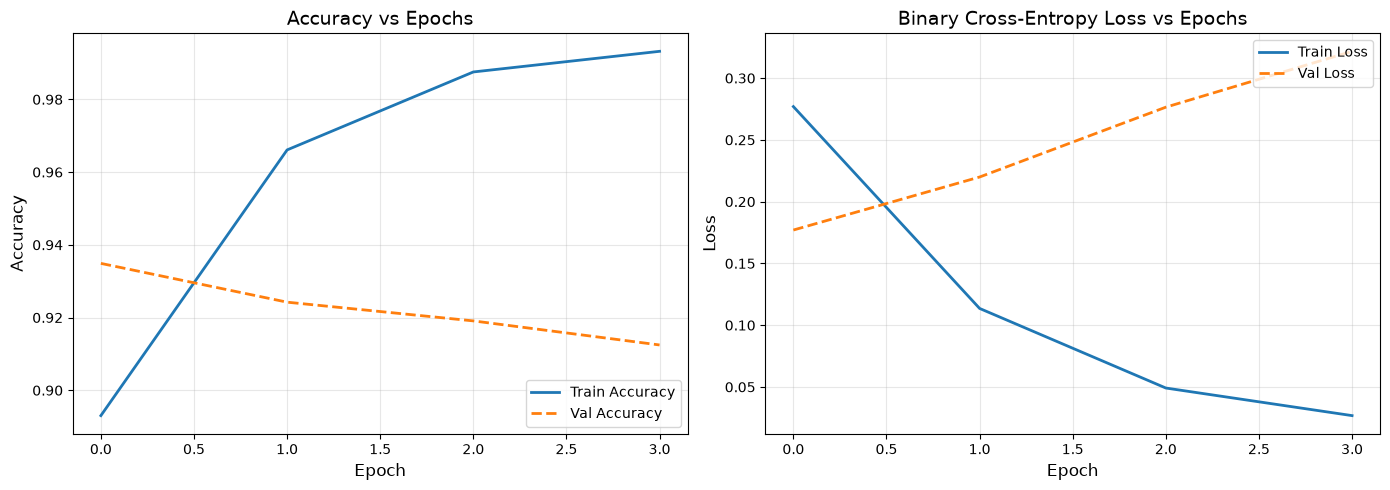

In [19]:
# Plot Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2, linestyle='--')
axes[0].set_title('Accuracy vs Epochs', fontsize=14)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# Loss Curve
axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss', linewidth=2, linestyle='--')
axes[1].set_title('Binary Cross-Entropy Loss vs Epochs', fontsize=14)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

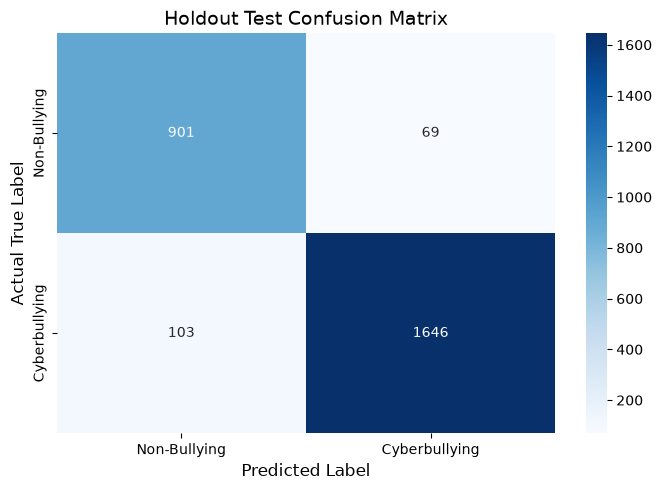

In [20]:
# Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Bullying', 'Cyberbullying'],
    yticklabels=['Non-Bullying', 'Cyberbullying']
)
plt.title('Holdout Test Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual True Label', fontsize=12)
plt.tight_layout()
plt.show()

## 14. Model Saving
To prepare for the future Flask backend and React web chat deployment, we serialize:
1. `cyberbullying_cnn.keras`: The trained Keras CNN model.
2. `tokenizer.pickle`: The fitted Tokenizer instance containing word indices.
3. `preprocessing_config.json`: Inference hyperparameters (max sequence length, vocab size, padding types, class mappings).

In [21]:
# 1. Save trained CNN model in native Keras format
MODEL_SAVE_PATH = 'cyberbullying_cnn.keras'
model.save(MODEL_SAVE_PATH)
print(f"Trained CNN model saved to: {MODEL_SAVE_PATH}")

# 2. Save fitted Tokenizer
TOKENIZER_SAVE_PATH = 'tokenizer.pickle'
with open(TOKENIZER_SAVE_PATH, 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Fitted Tokenizer saved to: {TOKENIZER_SAVE_PATH}")

# 3. Save preprocessing and metadata configuration
CONFIG_SAVE_PATH = 'preprocessing_config.json'
config_payload = {
    "max_vocab_size": MAX_VOCAB_SIZE,
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "embedding_dim": EMBEDDING_DIM,
    "padding_type": PADDING_TYPE,
    "truncating_type": TRUNC_TYPE,
    "oov_token": OOV_TOKEN,
    "label_mapping": LABEL_MAPPING,
    "classes": {
        0: "Non-Bullying",
        1: "Cyberbullying"
    }
}

with open(CONFIG_SAVE_PATH, 'w', encoding='utf-8') as f:
    json.dump(config_payload, f, indent=4)
print(f"Inference configuration saved to: {CONFIG_SAVE_PATH}")

Trained CNN model saved to: cyberbullying_cnn.keras
Fitted Tokenizer saved to: tokenizer.pickle
Inference configuration saved to: preprocessing_config.json


## 15. Conclusion & Viva Discussion Points
### Summary of Pipeline Achievements:
1. **Tailored for Hinglish & English:** The text preprocessing pipeline respects informal social media jargon, preserves crucial negation terms (`nahi`, `not`, `mat`), and avoids filtering abusive keywords needed for pattern detection.
2. **Rigorous Data Hygiene:** Train/Val/Test splitting (70/15/15) is stratified and strictly executed before fitting the tokenizer, guaranteeing zero data leakage.
3. **Custom 1D CNN Trained From Scratch:** Fast, low-latency convolutional feature extraction capable of recognizing multi-word abusive n-grams without bloated pretrained transformer weights.
4. **Class Imbalance Addressed:** Class weighting ensures equal penalization of errors on minority samples.
5. **Clean Serialization:** Exports the trained `.keras` model, `tokenizer.pickle`, and `preprocessing_config.json` for seamless integration into the upcoming Flask inference server and React frontend.